In [1]:
# %% 0. Paquetes y rutas relativas ====================================

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import jarque_bera, probplot

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss

# ---- Rutas relativas -------------------------------------------------
# El notebook busca el CSV en la carpeta donde está el notebook (o en una subcarpeta "datos").
def ubicar_csv(nombre="despachocemento.csv"):
    base = Path.cwd()
    candidatos = [base / nombre, base / "datos" / nombre,
                  base.parent / nombre, base.parent / "datos" / nombre]
    for ruta in candidatos:
        if ruta.exists():
            return ruta
    raise FileNotFoundError(
        f"No encontré {nombre}. Ponga el CSV en la misma carpeta del notebook "
        f"(carpeta actual: {base})."
    )

RUTA_CSV = ubicar_csv()
CARPETA_RESULTADOS = RUTA_CSV.parent / "resultados"
CARPETA_RESULTADOS.mkdir(exist_ok=True)   # aquí se guardan las figuras y tablas
print("Datos:", RUTA_CSV)
print("Resultados se guardan en:", CARPETA_RESULTADOS)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True})


# ---- Funciones auxiliares (se usan varias veces más abajo) ----------------
def guardar_figura(nombre):
    """Guarda la figura actual en resultados/ (alta resolución, para el póster)."""
    plt.savefig(CARPETA_RESULTADOS / f"{nombre}.png", dpi=200, bbox_inches="tight")


def graficar_fac_facp(serie, titulo, lags=24, nombre_archivo=None):
    """Dibuja FAC y FACP lado a lado. Bandas = +/- 1.96/sqrt(T) (95%)."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    plot_acf(serie, lags=lags, alpha=0.05, bartlett_confint=False, ax=axes[0])
    axes[0].set_title(f"FAC – {titulo}")
    plot_pacf(serie, lags=lags, alpha=0.05, ax=axes[1])
    axes[1].set_title(f"FACP – {titulo}")
    plt.tight_layout()
    if nombre_archivo:
        guardar_figura(nombre_archivo)
    plt.show()


def pruebas_raiz_unitaria(serie, nombre, regresion="c"):
    """DF, ADF y KPSS.  regresion='c' (solo constante) o 'ct' (constante + tendencia).
    ADF:  H0 = hay raíz unitaria (NO estacionaria).  p<0.05 -> estacionaria.
    KPSS: H0 = la serie ES estacionaria.             p<0.05 -> NO estacionaria."""
    print(f"===== {nombre}  (componentes deterministas: '{regresion}') =====")

    df_simple = adfuller(serie, regression=regresion, maxlag=0)
    print(f"DF Simple  | estadístico = {df_simple[0]:.4f} | p-valor = {df_simple[1]:.4f} | rezagos = {df_simple[2]}")
    print("           Valores críticos:", {k: round(v, 3) for k, v in df_simple[4].items()})
    print("           ->", "Rechazo H0: estacionaria" if df_simple[1] < 0.05 else "No rechazo H0: hay raíz unitaria (no estacionaria)")
    print("-" * 65)

    adf = adfuller(serie, regression=regresion)
    print(f"ADF  | estadístico = {adf[0]:.4f} | p-valor = {adf[1]:.4f} | rezagos = {adf[2]}")
    print("      valores críticos:", {k: round(v, 3) for k, v in adf[4].items()})
    print("      ->", "Rechazo H0: estacionaria" if adf[1] < 0.05
          else "No rechazo H0: hay raíz unitaria (no estacionaria)")
    print("-" * 65)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")   # KPSS avisa cuando el p-valor se sale de la tabla
        k = kpss(serie, regression=regresion, nlags="auto")
    print(f"KPSS | estadístico = {k[0]:.4f} | p-valor = {k[1]:.4f} | rezagos = {k[2]}")
    print("      valores críticos:", k[3])
    print("      ->", "Rechazo H0: NO estacionaria" if k[1] < 0.05
          else "No rechazo H0: estacionaria")
    print()

Datos: C:\Users\angel\TRABAJOBOXJENKINS\DATOS\despachocemento.csv
Resultados se guardan en: C:\Users\angel\TRABAJOBOXJENKINS\DATOS\resultados


In [2]:
# %% 1. Carga y limpieza ===============================================

cemento_base = pd.read_csv(
    RUTA_CSV,
    sep=";",              # columnas separadas por punto y coma
    thousands=".",        # 1.066.270 -> 1066270 (el punto es separador de miles)
    header=0,             # la primera fila es el encabezado...
    names=["periodo", "toneladas"],   # ...y la renombramos
    encoding="utf-8-sig",
)

# Fechas con formato mes/día/año -> las llevamos al primer día de cada mes
fechas = pd.to_datetime(cemento_base["periodo"], format="mixed")
fechas = pd.DatetimeIndex(fechas).to_period("M").to_timestamp()

cemento_serie = pd.Series(
    cemento_base["toneladas"].astype(float).values,
    index=pd.DatetimeIndex(fechas, freq="MS"),   # frecuencia mensual
    name="toneladas",
)

# Verificaciones: sin faltantes, sin fechas repetidas y todos los meses consecutivos
assert cemento_serie.notna().all(), "Hay datos faltantes"
assert cemento_serie.index.is_unique, "Hay fechas repetidas"
assert len(pd.date_range(cemento_serie.index[0], cemento_serie.index[-1], freq="MS")) == len(cemento_serie), \
    "Faltan meses en la serie"

print("Observaciones (T):", len(cemento_serie))
print("Periodo:", cemento_serie.index[0].strftime("%Y-%m"), "a", cemento_serie.index[-1].strftime("%Y-%m"))
print(cemento_serie.head())
print(cemento_serie.tail())

Observaciones (T): 209
Periodo: 2009-01 a 2026-05
periodo
2009-01-01    678661.0
2009-02-01    695755.0
2009-03-01    635399.0
2009-04-01    741963.0
2009-05-01    700399.0
Freq: MS, Name: toneladas, dtype: float64
periodo
2026-01-01    1066270.0
2026-02-01    1144098.0
2026-03-01    1061625.0
2026-04-01    1157860.0
2026-05-01    1130280.0
Freq: MS, Name: toneladas, dtype: float64


In [3]:
# %% 2. Descripción de la serie ===========================================

print(cemento_serie.describe().round(0))
print("\nMáximo:", int(cemento_serie.max()), "toneladas en", cemento_serie.idxmax().strftime("%Y-%m"))
print("Mínimo:", int(cemento_serie.min()), "toneladas en", cemento_serie.idxmin().strftime("%Y-%m"))

count        209.0
mean      979386.0
std       143165.0
min       242414.0
25%       905881.0
50%      1007968.0
75%      1084450.0
max      1257125.0
Name: toneladas, dtype: float64

Máximo: 1257125 toneladas en 2021-12
Mínimo: 242414 toneladas en 2020-01


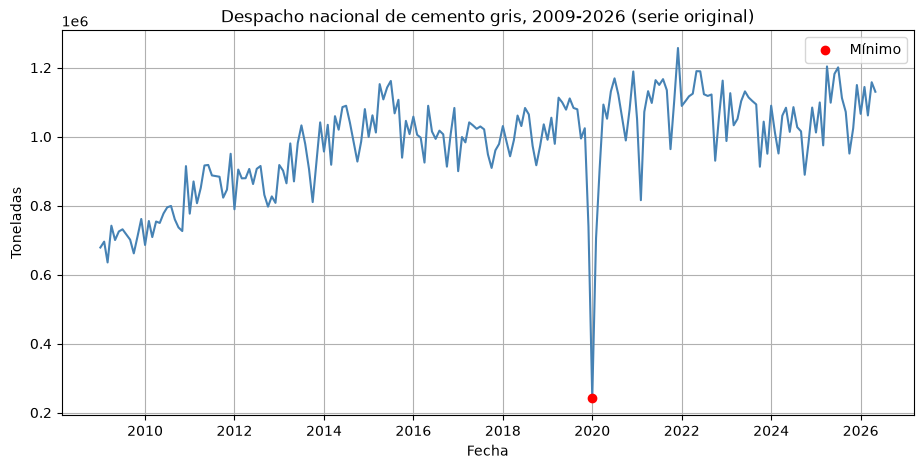

In [4]:
# %% 3. Gráfica de la serie original ======================================

plt.figure(figsize=(11, 5))
plt.plot(cemento_serie, color="steelblue")
plt.scatter(cemento_serie.idxmin(), cemento_serie.min(), color="red", zorder=3, label="Mínimo")
plt.title("Despacho nacional de cemento gris, 2009-2026 (serie original)")
plt.xlabel("Fecha")
plt.ylabel("Toneladas")
plt.legend()
guardar_figura("01_serie_original")
plt.show()

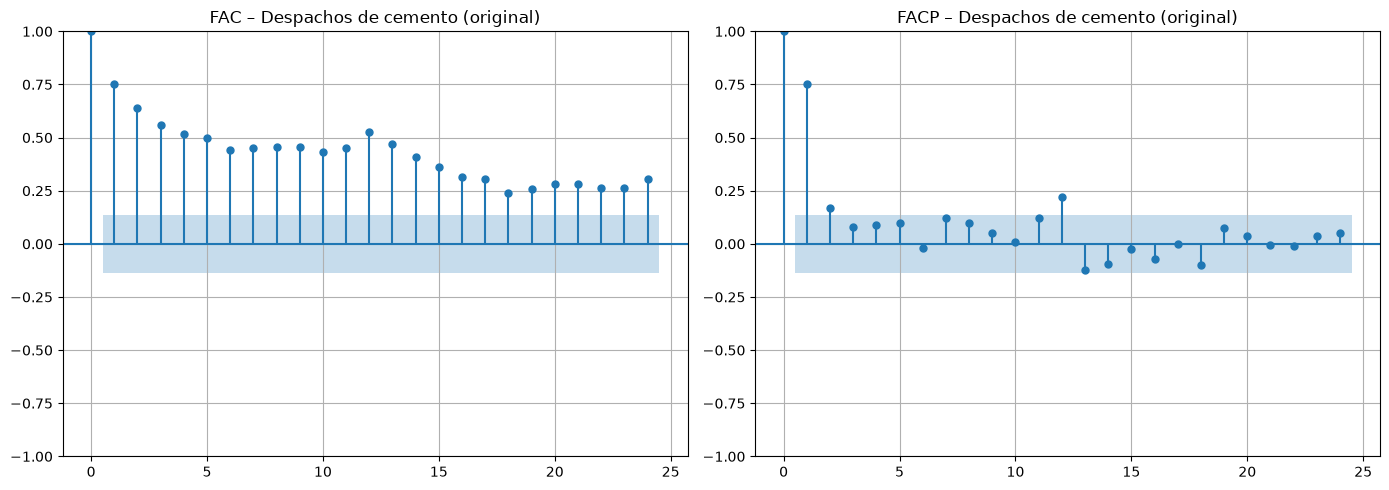

In [5]:
# %% 4a. FAC y FACP de la serie original ===================================
graficar_fac_facp(cemento_serie, "Despachos de cemento (original)", nombre_archivo="02_fac_facp_original")

In [6]:
# %% 4b. Pruebas de raíz unitaria sobre la serie original ===================
pruebas_raiz_unitaria(cemento_serie, "Serie original", regresion="c")
pruebas_raiz_unitaria(cemento_serie, "Serie original", regresion="ct")

===== Serie original  (componentes deterministas: 'c') =====
DF Simple  | estadístico = -5.4711 | p-valor = 0.0000 | rezagos = 0
           Valores críticos: {'1%': np.float64(-3.462), '5%': np.float64(-2.876), '10%': np.float64(-2.574)}
           -> Rechazo H0: estacionaria
-----------------------------------------------------------------
ADF  | estadístico = -2.3180 | p-valor = 0.1662 | rezagos = 11
      valores críticos: {'1%': np.float64(-3.464), '5%': np.float64(-2.876), '10%': np.float64(-2.575)}
      -> No rechazo H0: hay raíz unitaria (no estacionaria)
-----------------------------------------------------------------
KPSS | estadístico = 1.6140 | p-valor = 0.0100 | rezagos = 8
      valores críticos: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}
      -> Rechazo H0: NO estacionaria

===== Serie original  (componentes deterministas: 'ct') =====
DF Simple  | estadístico = -7.4590 | p-valor = 0.0000 | rezagos = 0
           Valores críticos: {'1%': np.float64(-4.003),

Observaciones de la serie transformada: 208
count    208.0000
mean       0.0025
std        0.1398
min       -1.1156
25%       -0.0575
50%       -0.0029
75%        0.0623
max        1.0689
Name: toneladas, dtype: float64


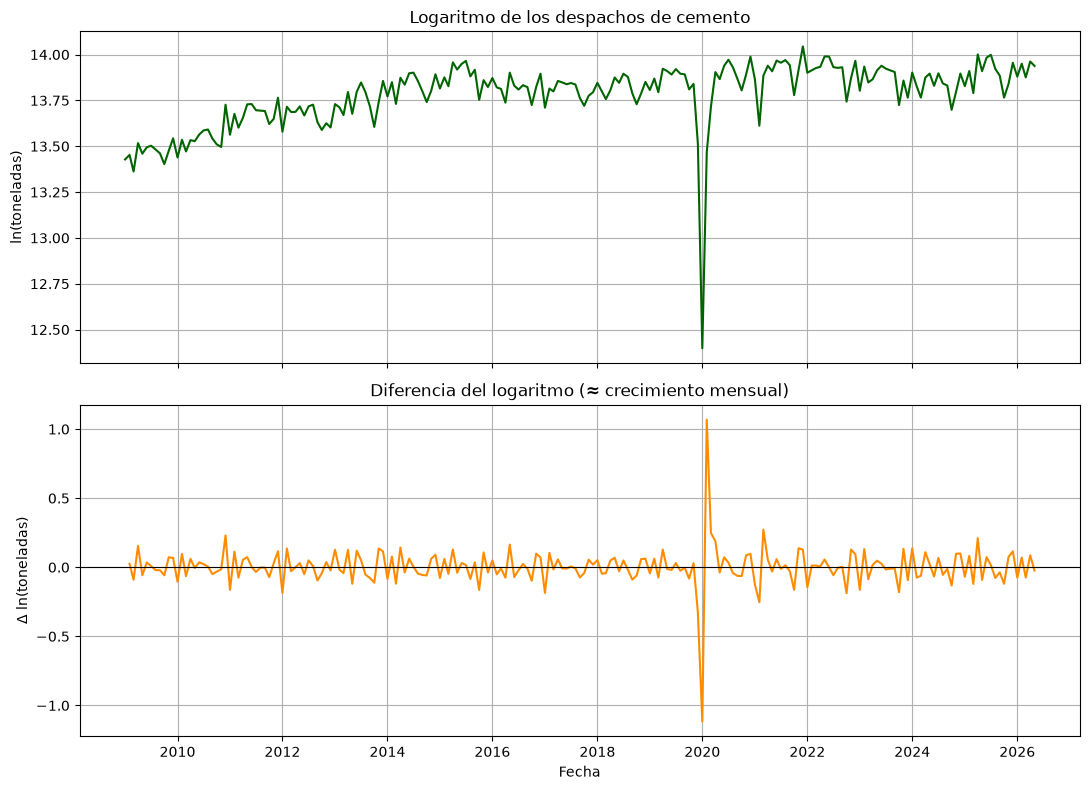

In [7]:
# %% 5. Transformación: logaritmo y diferencia del logaritmo ===============

log_serie = np.log(cemento_serie)                 # logaritmo natural de la serie original
dlog_serie = log_serie.diff().dropna()            # diferencia del logaritmo (≈ crecimiento mensual)

print("Observaciones de la serie transformada:", len(dlog_serie))
print(dlog_serie.describe().round(4))

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
axes[0].plot(log_serie, color="darkgreen")
axes[0].set_title("Logaritmo de los despachos de cemento")
axes[0].set_ylabel("ln(toneladas)")
axes[1].plot(dlog_serie, color="darkorange")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("Diferencia del logaritmo (≈ crecimiento mensual)")
axes[1].set_xlabel("Fecha")
axes[1].set_ylabel("Δ ln(toneladas)")
plt.tight_layout()
guardar_figura("03_transformacion_log_diff")
plt.show()

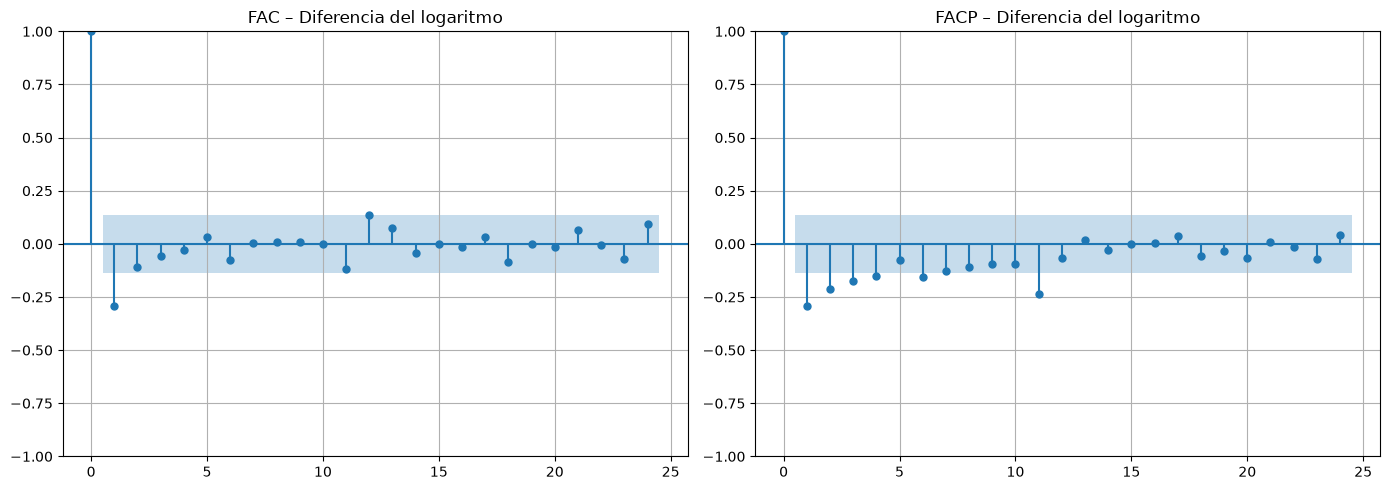

In [8]:
# %% 6a. FAC y FACP de la diferencia del logaritmo =========================
graficar_fac_facp(dlog_serie, "Diferencia del logaritmo", nombre_archivo="04_fac_facp_transformada")

In [9]:
# %% 6b. Pruebas de raíz unitaria sobre la serie transformada ===============
pruebas_raiz_unitaria(dlog_serie, "Diferencia del logaritmo", regresion="c")

===== Diferencia del logaritmo  (componentes deterministas: 'c') =====
DF Simple  | estadístico = -19.3558 | p-valor = 0.0000 | rezagos = 0
           Valores críticos: {'1%': np.float64(-3.462), '5%': np.float64(-2.876), '10%': np.float64(-2.574)}
           -> Rechazo H0: estacionaria
-----------------------------------------------------------------
ADF  | estadístico = -8.1359 | p-valor = 0.0000 | rezagos = 10
      valores críticos: {'1%': np.float64(-3.464), '5%': np.float64(-2.876), '10%': np.float64(-2.575)}
      -> Rechazo H0: estacionaria
-----------------------------------------------------------------
KPSS | estadístico = 0.1465 | p-valor = 0.1000 | rezagos = 40
      valores críticos: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}
      -> No rechazo H0: estacionaria



In [10]:
# %% 7a. Estimación de los modelos candidatos ==============================

candidatos = [(0, 1, 1), (1, 1, 1), (0, 1, 2), (2, 1, 1), (1, 1, 2)]
estimaciones = {}
filas = []

for orden in candidatos:
    p, d, q = orden
    modelo = SARIMAX(log_serie, order=orden, trend="n")   # se especifica el modelo
    resultado = modelo.fit(disp=False)                    # se estima por máxima verosimilitud
    estimaciones[orden] = resultado

    # Residuales sin el primero (con d=1 el primer residual no es un error de predicción real)
    resid = resultado.resid.iloc[d:]
    lb = acorr_ljungbox(resid, lags=[12, 24], model_df=p + q, return_df=True)

    filas.append({
        "modelo": f"ARIMA{orden}",
        "AIC": resultado.aic,
        "BIC": resultado.bic,
        "log-verosimilitud": resultado.llf,
        "todos los coef. significativos (5%)": bool((resultado.pvalues.drop("sigma2") < 0.05).all()),
        "Ljung-Box p (rez. 12)": lb["lb_pvalue"].iloc[0],
        "Ljung-Box p (rez. 24)": lb["lb_pvalue"].iloc[1],
    })

tabla_modelos = pd.DataFrame(filas).set_index("modelo").round(4)
print(tabla_modelos)
tabla_modelos.to_csv(CARPETA_RESULTADOS / "tabla_comparacion_modelos.csv")

C:\Users\angel\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                     AIC       BIC  log-verosimilitud  \
modelo                                                  
ARIMA(0, 1, 1) -259.6167 -252.9416           131.8084   
ARIMA(1, 1, 1) -278.4501 -268.4375           142.2251   
ARIMA(0, 1, 2) -275.2506 -265.2380           140.6253   
ARIMA(2, 1, 1) -276.4595 -263.1094           142.2298   
ARIMA(1, 1, 2) -276.4583 -263.1082           142.2292   

                todos los coef. significativos (5%)  Ljung-Box p (rez. 12)  \
modelo                                                                       
ARIMA(0, 1, 1)                                 True                 0.0025   
ARIMA(1, 1, 1)                                 True                 0.5726   
ARIMA(0, 1, 2)                                 True                 0.2222   
ARIMA(2, 1, 1)                                False                 0.4761   
ARIMA(1, 1, 2)                                False                 0.4762   

                Ljung-Box p (rez. 24)  
modelo       

In [11]:
# %% 7b. Modelo elegido ====================================================

ORDEN_ELEGIDO = (1, 1, 1)          # <- cámbielo si la tabla anterior indica otro modelo
estimacion = estimaciones[ORDEN_ELEGIDO]
p, d, q = ORDEN_ELEGIDO

print(estimacion.summary())

                               SARIMAX Results                                
Dep. Variable:              toneladas   No. Observations:                  209
Model:               SARIMAX(1, 1, 1)   Log Likelihood                 142.225
Date:                Fri, 23 Oct 2026   AIC                           -278.450
Time:                        21:05:38   BIC                           -268.438
Sample:                    01-01-2009   HQIC                          -274.402
                         - 05-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3953      0.056      7.102      0.000       0.286       0.504
ma.L1         -0.9055      0.046    -19.746      0.000      -0.995      -0.816
sigma2         0.0148      0.000     41.433      0.0

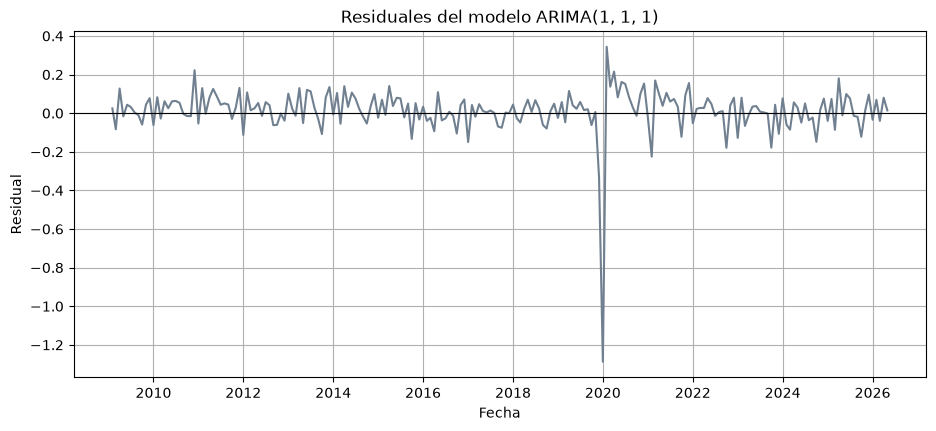

count    208.0000
mean       0.0140
std        0.1214
min       -1.2875
25%       -0.0242
50%        0.0236
75%        0.0717
max        0.3440
dtype: float64


In [12]:
# %% 8a. Residuales: gráfica y descripción =================================

residuales = estimacion.resid.iloc[d:]     # quitamos las primeras d observaciones

plt.figure(figsize=(11, 4.5))
plt.plot(residuales, color="slategray")
plt.axhline(0, color="black", lw=0.8)
plt.title(f"Residuales del modelo ARIMA{ORDEN_ELEGIDO}")
plt.xlabel("Fecha")
plt.ylabel("Residual")
guardar_figura("05_residuales")
plt.show()

print(residuales.describe().round(4))

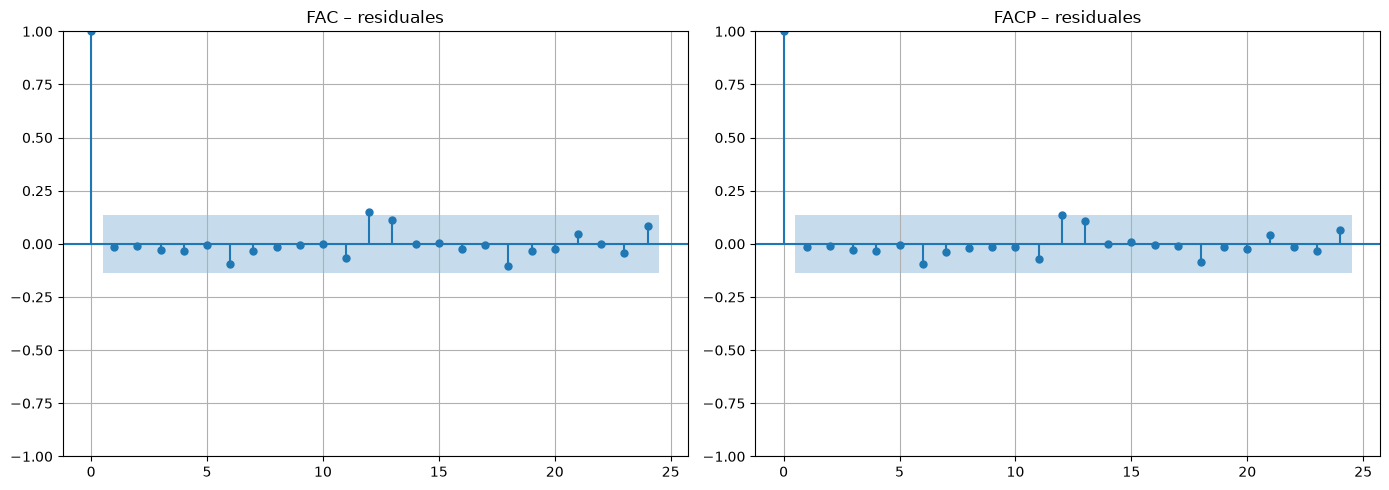

In [13]:
# %% 8b. FAC y FACP de los residuales ======================================
graficar_fac_facp(residuales, "residuales", nombre_archivo="06_fac_facp_residuales")

In [14]:
# %% 8c. Prueba Ljung-Box (autocorrelación de los residuales) ==============
# H0: los residuales NO están autocorrelacionados (ruido blanco).
# p-valor > 0.05  -> no se rechaza H0 (bien).
# model_df = p + q corrige los grados de libertad por los parámetros estimados.

ljung_box = acorr_ljungbox(residuales, lags=[6, 12, 18, 24], model_df=p + q, return_df=True)
print("Prueba Ljung-Box")
print(ljung_box.round(4))

Prueba Ljung-Box
    lb_stat  lb_pvalue
6    2.4609     0.6517
12   8.5779     0.5726
18  13.9069     0.6056
24  16.9057     0.7685


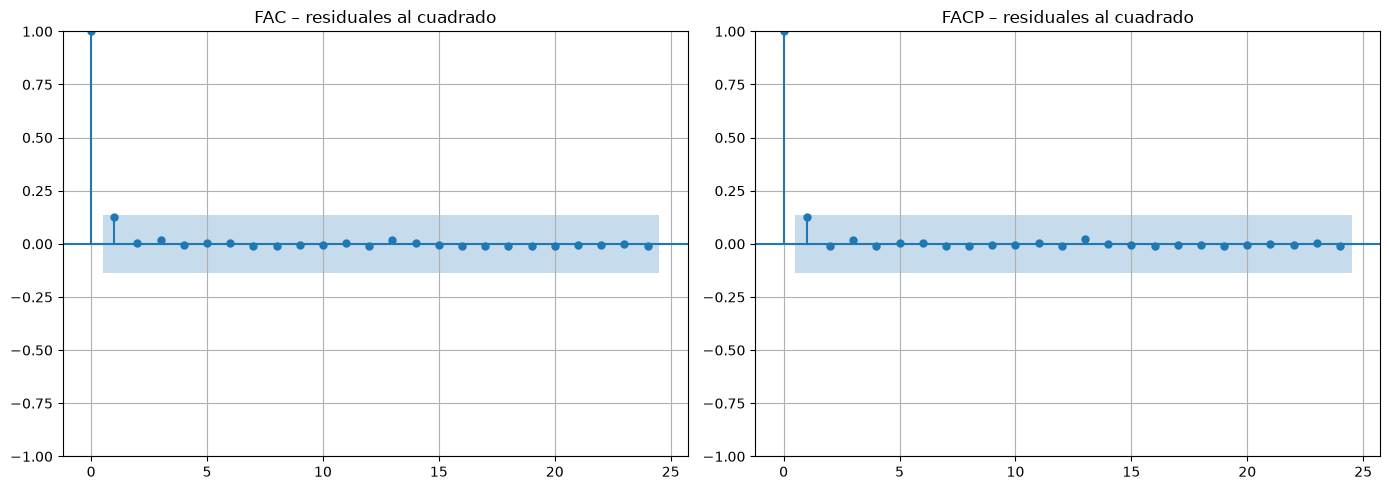

In [15]:
# %% 8d. FAC y FACP de los residuales al cuadrado ==========================
# Si el cuadrado de los residuales está autocorrelacionado hay heterocedasticidad condicional (efectos ARCH).
graficar_fac_facp(residuales ** 2, "residuales al cuadrado", nombre_archivo="07_fac_facp_residuales_cuadrado")

In [16]:
# %% 8e. Prueba ARCH (varianza constante) ==================================
# H0: NO hay efectos ARCH (varianza constante).  p-valor > 0.05 -> no se rechaza H0 (bien).

arch_test = het_arch(residuales, nlags=12)
print("Prueba ARCH (12 rezagos)")
print("Estadístico LM:", round(arch_test[0], 4))
print("p-valor LM:", round(arch_test[1], 4))

Prueba ARCH (12 rezagos)
Estadístico LM: 3.2064
p-valor LM: 0.9939


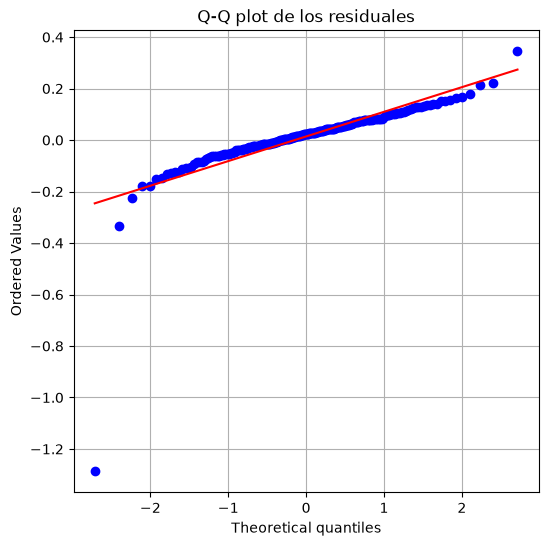

Prueba Jarque-Bera
Estadístico JB: 34737.3367
p-valor JB: 0.0
Asimetría: -6.0198 | Curtosis (exceso): 63.7217


In [17]:
# %% 8f. Normalidad: Q-Q plot y Jarque-Bera ================================
# Jarque-Bera: H0 = los residuales SÍ siguen una distribución normal.
# p-valor < 0.05 -> se rechaza H0 (no hay normalidad).

fig, ax = plt.subplots(figsize=(6, 6))
probplot(residuales, dist="norm", plot=ax)
ax.set_title("Q-Q plot de los residuales")
guardar_figura("08_qqplot_residuales")
plt.show()

jb_test = jarque_bera(residuales)
print("Prueba Jarque-Bera")
print("Estadístico JB:", round(jb_test.statistic, 4))
print("p-valor JB:", round(jb_test.pvalue, 4))
print("Asimetría:", round(residuales.skew(), 4), "| Curtosis (exceso):", round(residuales.kurt(), 4))

In [18]:
# %% 8g. Estacionariedad e invertibilidad del modelo estimado ==============
# Las raíces de los polinomios AR y MA deben quedar FUERA del círculo unitario (módulo > 1).

print("Módulo de las raíces AR:", np.round(np.abs(estimacion.arroots), 4) if p > 0 else "no hay parte AR")
print("Módulo de las raíces MA:", np.round(np.abs(estimacion.maroots), 4) if q > 0 else "no hay parte MA")

Módulo de las raíces AR: [2.5299]
Módulo de las raíces MA: [1.1044]


In [19]:
# %% 9. Tabla resumen de la validación ======================================

lb12 = acorr_ljungbox(residuales, lags=[12], model_df=p + q)["lb_pvalue"].iloc[0]
lb24 = acorr_ljungbox(residuales, lags=[24], model_df=p + q)["lb_pvalue"].iloc[0]
arch_p = het_arch(residuales, nlags=12)[1]
jb_p = jarque_bera(residuales).pvalue
raices_ok = bool((np.abs(estimacion.arroots) > 1).all() and (np.abs(estimacion.maroots) > 1).all())
coef_sig = bool((estimacion.pvalues.drop("sigma2") < 0.05).all())

def veredicto(cumple):
    return "Cumple ✔" if cumple else "No cumple ✘"

resumen = pd.DataFrame([
    ["Coeficientes significativos", "z / p-valor < 0.05", "todos" if coef_sig else "alguno no significativo", veredicto(coef_sig)],
    ["Estacionariedad e invertibilidad", "raíces fuera del círculo unitario", "módulos > 1" if raices_ok else "alguna raíz ≤ 1", veredicto(raices_ok)],
    ["Sin autocorrelación", "Ljung-Box rezago 12", round(lb12, 4), veredicto(lb12 > 0.05)],
    ["Sin autocorrelación", "Ljung-Box rezago 24", round(lb24, 4), veredicto(lb24 > 0.05)],
    ["Varianza constante", "ARCH (12 rezagos)", round(arch_p, 4), veredicto(arch_p > 0.05)],
    ["Normalidad", "Jarque-Bera", round(jb_p, 4), veredicto(jb_p > 0.05)],
], columns=["Supuesto", "Prueba", "p-valor / resultado", "Conclusión (5%)"])

print(resumen.to_string(index=False))
resumen.to_csv(CARPETA_RESULTADOS / "tabla_validacion_supuestos.csv", index=False)

                        Supuesto                            Prueba p-valor / resultado Conclusión (5%)
     Coeficientes significativos                z / p-valor < 0.05               todos        Cumple ✔
Estacionariedad e invertibilidad raíces fuera del círculo unitario         módulos > 1        Cumple ✔
             Sin autocorrelación               Ljung-Box rezago 12              0.5726        Cumple ✔
             Sin autocorrelación               Ljung-Box rezago 24              0.7685        Cumple ✔
              Varianza constante                 ARCH (12 rezagos)              0.9939        Cumple ✔
                      Normalidad                       Jarque-Bera                 0.0     No cumple ✘


         pronostico_toneladas  limite_inferior_95  limite_superior_95
2026-06             1113441.0            870452.0           1403278.0
2026-07             1105579.0            839699.0           1429104.0
2026-08             1102390.0            829467.0           1436630.0
2026-09             1101219.0            824622.0           1441071.0
2026-10             1100872.0            821556.0           1444867.0
2026-11             1100855.0            819148.0           1448486.0
2026-12             1100968.0            817005.0           1452037.0
2027-01             1101134.0            814978.0           1455552.0
2027-02             1101320.0            813007.0           1459040.0
2027-03             1101515.0            811072.0           1462507.0


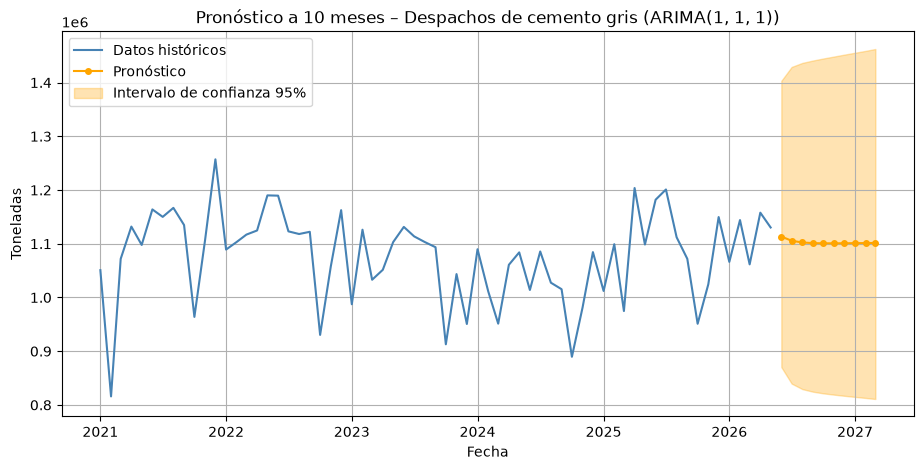

In [20]:
# %% 10. Pronóstico a 10 meses =============================================

pasos = 10
pronostico = estimacion.get_forecast(steps=pasos)

media_log = pronostico.predicted_mean              # pronóstico puntual en logaritmos
var_log = pronostico.var_pred_mean                 # varianza del error de pronóstico (en logs)
intervalo_log = pronostico.conf_int(alpha=0.05)    # intervalo del 95% en logaritmos

# Retransformación a toneladas
pronostico_nivel = np.exp(media_log + 0.5 * var_log)     # media (con corrección por sesgo)
limite_inf = np.exp(intervalo_log.iloc[:, 0])
limite_sup = np.exp(intervalo_log.iloc[:, 1])

tabla_pronostico = pd.DataFrame({
    "pronostico_toneladas": pronostico_nivel,
    "limite_inferior_95": limite_inf,
    "limite_superior_95": limite_sup,
}).round(0)
tabla_pronostico.index = tabla_pronostico.index.strftime("%Y-%m")
print(tabla_pronostico)
tabla_pronostico.to_csv(CARPETA_RESULTADOS / "tabla_pronostico.csv")

# Gráfica: últimos 5 años de datos + pronóstico
historia = cemento_serie["2021-01-01":]
plt.figure(figsize=(11, 5))
plt.plot(historia, label="Datos históricos", color="steelblue")
plt.plot(pronostico_nivel, label="Pronóstico", color="orange", marker="o", ms=4)
plt.fill_between(pronostico_nivel.index, limite_inf, limite_sup,
                 color="orange", alpha=0.3, label="Intervalo de confianza 95%")
plt.title(f"Pronóstico a {pasos} meses – Despachos de cemento gris (ARIMA{ORDEN_ELEGIDO})")
plt.xlabel("Fecha")
plt.ylabel("Toneladas")
plt.legend()
guardar_figura("09_pronostico")
plt.show()